In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from src.data.loader import load_raw_data, basic_clean
from src.features.engineering import add_behavioural_features, build_features_target
from src.features.splitting import stratified_split
from src.models.pipe import build_pipeline
from src.models.trainer import cross_validate
from src.models.registry import MODEL_REGISTRY
from src.utils.metrics import evaluate_classifier

df = basic_clean(load_raw_data())
df = add_behavioural_features(df)
X, y = build_features_target(df)
X_train, X_test, y_train, y_test = stratified_split(X, y)
print(f'train {X_train.shape} | test {X_test.shape}')

2026-11-01 16:19:39,961 | INFO     | src.data.loader | load_raw_data:110 | Loading dataset from C:\All\why\data\raw\UCI_Credit_Card.csv


train (24000, 61) | test (6000, 61)


## Cross-validate all 5 models (compact leaderboard)

Same `cross_validate` helper as the production pipeline (5-fold stratified
CV on the 24k-row training set). It takes a few minutes on CPU. Reduce
`n_splits` only for a quick local smoke run, and report the setting used.

In [2]:
num_features = X_train.select_dtypes(include='number').columns.tolist()
rows = []
for name in MODEL_REGISTRY:
    pipe = build_pipeline(name, num_features=num_features)
    summary = cross_validate(pipe, X_train, y_train, n_splits=5)
    rows.append({'model': name, **summary['mean']})
result_cv = pd.DataFrame(rows).sort_values(by='roc_auc', ascending=False).set_index('model')
result_cv.round(4)

2026-11-01 16:19:41,207 | INFO     | src.models.trainer | cross_validate:48 | Fold 1 | ROC AUC 0.7711 | PR AUC 0.5110 | F1 0.5350


2026-11-01 16:19:42,059 | INFO     | src.models.trainer | cross_validate:48 | Fold 2 | ROC AUC 0.7679 | PR AUC 0.5321 | F1 0.5221


2026-11-01 16:19:43,017 | INFO     | src.models.trainer | cross_validate:48 | Fold 3 | ROC AUC 0.7611 | PR AUC 0.5036 | F1 0.5193


2026-11-01 16:19:43,975 | INFO     | src.models.trainer | cross_validate:48 | Fold 4 | ROC AUC 0.7603 | PR AUC 0.5020 | F1 0.5197


2026-11-01 16:19:45,078 | INFO     | src.models.trainer | cross_validate:48 | Fold 5 | ROC AUC 0.7659 | PR AUC 0.4929 | F1 0.5348


2026-11-01 16:20:06,303 | INFO     | src.models.trainer | cross_validate:48 | Fold 1 | ROC AUC 0.7750 | PR AUC 0.5493 | F1 0.5455


... (18 outputs left out)

2026-11-01 16:22:39,798 | INFO     | src.models.trainer | cross_validate:48 | Fold 3 | ROC AUC 0.7669 | PR AUC 0.5410 | F1 0.5204


2026-11-01 16:22:57,873 | INFO     | src.models.trainer | cross_validate:48 | Fold 4 | ROC AUC 0.7855 | PR AUC 0.5560 | F1 0.5361


2026-11-01 16:23:15,874 | INFO     | src.models.trainer | cross_validate:48 | Fold 5 | ROC AUC 0.7839 | PR AUC 0.5539 | F1 0.5339


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
xgboost,0.7793,0.5011,0.6048,0.5481,0.7886,0.5629
lightgbm,0.7600,0.4690,0.6427,0.5423,0.7872,0.5632
catboost,0.7672,0.4794,0.6071,0.5357,0.7802,0.5571
random_forest,0.7940,0.5344,0.5363,0.5353,0.7744,0.5451
logistic_regression,0.7496,0.4525,0.6286,0.5262,0.7653,0.5083


## Train a single LightGBM model and inspect test scores

In [3]:
pipe = build_pipeline('lightgbm', num_features=num_features)
pipe.fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]
preds = pipe.predict(X_test)
pd.Series(evaluate_classifier(y_test.values, preds, proba)).round(4)

2026-11-01 16:23:15,908 | INFO     | src.models.registry | _apply_tuned:52 | Using tuned hyperparameters for lightgbm: {'n_estimators': 284, 'learning_rate': 0.03216078419470535, 'num_leaves': 57, 'max_depth': 3, 'min_child_samples': 23, 'subsample': 0.644639302316432, 'colsample_bytree': 0.816259298663039, 'reg_lambda': 0.0377837566557612}


accuracy     0.7583
precision    0.4661
recall       0.6368
f1           0.5382
roc_auc      0.7828
pr_auc       0.5625
dtype: float64

## Confusion matrix + ROC / PR curves

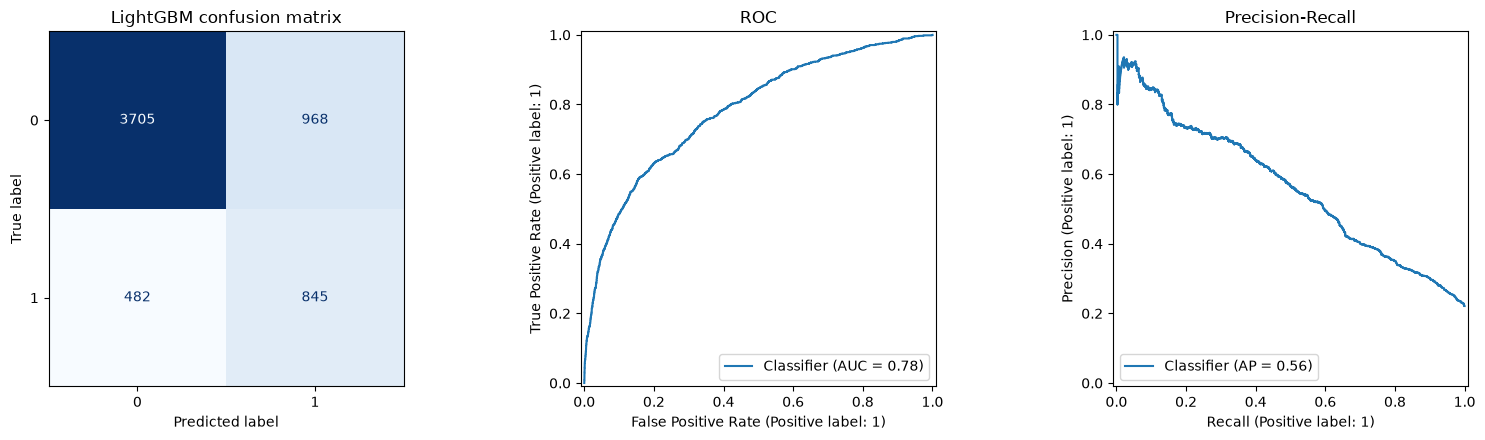

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('LightGBM confusion matrix')
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1])
axes[1].set_title('ROC')
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2])
axes[2].set_title('Precision-Recall')
plt.tight_layout()
plt.savefig('../reports/figures/03_lightgbm_curves.png', dpi=110)
plt.show()